# Online Shopping Order Value Analysis – Data Analyst Project

**Student:** Siddhant Chauhan | **Admission No:** 2026B01010381 | **Branch/Section:** CSE-13 | **Date:** 21-11-2026

**Audience:** Sales and marketing team of an online store | **Tools:** Python, pandas, matplotlib, seaborn

## 1. Business problem

The sales and marketing team of an online store wants to understand **what makes an order bigger or smaller**, so that they can decide where to spend the promotion budget and which low-value orders need attention.

**Questions we will answer**

1. What does `Order_Value_INR` look like overall?
2. Do `Items_Count` and `Time_On_Site_Min` affect order value? (Also check `Discount_Percent` and `Delivery_Days`.)
3. Does order value differ by product category, city, payment method or customer type?
4. Which orders are **Low Value** (order value below ₹1,500) and which groups do they cluster in?

> The dataset is **synthetic** (computer-generated, 255 rows in the raw file) and contains no real customer data.

## 2. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

## 3. Load and inspect the data

In [2]:
df = pd.read_csv('../data/raw/shopping_data.csv')
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (255, 11)


,Order_ID,Order_Date,City,Product_Category,Payment_Method,Customer_Type,Items_Count,Time_On_Site_Min,Discount_Percent,Delivery_Days,Order_Value_INR
0,O1034,2025-04-16,Bengaluru,Home_Kitchen,Cash_on_Delivery,New,2,29.6,17,4.0,2760
1,O1047,2025-04-28,Mumbai,Electronics,NaN,Returning,1,18.5,29,7.0,1720
2,O1014,2025-09-25,Delhi,Electronics,Cash_on_Delivery,New,1,22.2,15,4.0,2230
3,O1036,2025-07-10,Delhi,Electronics,UPI,New,3,17.7,1,5.0,5280
4,O1177,2025-09-20,Mumbai,Electronics,Credit_Card,Returning,2,27.0,13,2.0,3530


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          255 non-null    str    
 1   Order_Date        255 non-null    str    
 2   City              255 non-null    str    
 3   Product_Category  255 non-null    str    
 4   Payment_Method    249 non-null    str    
 5   Customer_Type     249 non-null    str    
 6   Items_Count       255 non-null    int64  
 7   Time_On_Site_Min  250 non-null    float64
 8   Discount_Percent  255 non-null    int64  
 9   Delivery_Days     251 non-null    float64
 10  Order_Value_INR   255 non-null    int64  
dtypes: float64(2), int64(3), str(6)
memory usage: 22.0 KB


In [4]:
print('Missing values per column:')
print(df.isna().sum()[df.isna().sum() > 0])
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().round(1)

Missing values per column:
Payment_Method      6
Customer_Type       6
Time_On_Site_Min    5
Delivery_Days       4
dtype: int64

Duplicate rows: 5


,Items_Count,Time_On_Site_Min,Discount_Percent,Delivery_Days,Order_Value_INR
count,255.0,250.0,255.0,251.0,255.0
mean,3.3,18.2,15.0,4.1,2605.0
std,1.5,6.9,11.0,1.6,1521.6
min,1.0,5.1,-20.0,1.0,150.0
25%,2.0,12.2,9.0,3.0,1505.0
50%,3.0,18.0,15.0,4.0,2520.0
75%,4.0,23.0,20.0,5.0,3725.0
max,8.0,38.9,135.0,8.0,6440.0


In [5]:
# look for messy text and impossible values
print('City values:', sorted(df['City'].dropna().unique()))
bad_disc = df.loc[(df['Discount_Percent'] < 0) | (df['Discount_Percent'] > 50), 'Discount_Percent']
print('Discount outside 0-50:', bad_disc.tolist())

City values: [' Jaipur ', ' Lucknow ', 'Bengaluru', 'DELHI', 'Delhi', 'Delhi  ', 'JAIPUR', 'Jaipur', 'Lucknow', 'Mumbai', 'bengaluru']
Discount outside 0-50: [-20, 135]


**What we found:** 5 duplicate rows, missing values in `Time_On_Site_Min` (5), `Delivery_Days` (4), `Payment_Method` (6) and `Customer_Type` (6), city names written in 11 different ways (extra spaces and capital letters, for example `DELHI`, `bengaluru`, `' Jaipur '`) and two impossible discounts (`-20` and `135`). We clean these next.

## 4. Clean the data

In [6]:
clean = df.copy()

# 1. Remove duplicate rows
clean = clean.drop_duplicates()

# 2. Standardise text (remove extra spaces, fix capital letters)
clean['City'] = clean['City'].str.strip().str.title()

# 3. Fix impossible values (discount must be between 0 and 50)
clean.loc[(clean['Discount_Percent'] < 0) | (clean['Discount_Percent'] > 50), 'Discount_Percent'] = np.nan

# 4. Fill missing numbers with the median (not affected by extreme values)
for c in ['Time_On_Site_Min', 'Delivery_Days', 'Discount_Percent']:
    clean[c] = clean[c].fillna(clean[c].median())

# 5. Fill missing categories with 'Unknown' instead of guessing
for c in ['Payment_Method', 'Customer_Type']:
    clean[c] = clean[c].fillna('Unknown')

# days and percent are whole numbers, so keep them as integers
clean['Delivery_Days'] = clean['Delivery_Days'].astype(int)
clean['Discount_Percent'] = clean['Discount_Percent'].astype(int)

clean = clean.sort_values('Order_ID').reset_index(drop=True)
print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())
print('Cities now:', sorted(clean['City'].unique()))
print('Discount range:', clean['Discount_Percent'].min(), 'to', clean['Discount_Percent'].max())

Rows after cleaning: 250 | Missing values left: 0
Cities now: ['Bengaluru', 'Delhi', 'Jaipur', 'Lucknow', 'Mumbai']
Discount range: 0 to 34


**Choices made:** the median is used for numbers because a few very long visits or deliveries would pull the mean. Missing categories become `Unknown` (a separate, very small group) because guessing a payment method or customer type could mislead the comparison. Cleaning leaves **250 unique orders (O1001 to O1250)**.

## 5. Create new columns (feature engineering)

In [7]:
# 1. Combined column: does a big order come from many items or from costly items?
clean['Value_Per_Item'] = (clean['Order_Value_INR'] / clean['Items_Count']).round(0)

# 2. Condition-based label
def segment(row):
    if row['Time_On_Site_Min'] > 25 and row['Items_Count'] >= 4:
        return 'Heavy Browser'
    if row['Time_On_Site_Min'] < 10:
        return 'Quick Buyer'
    return 'Regular'
clean['Order_Segment'] = clean.apply(segment, axis=1)

# 3. Binned column: delivery speed
clean['Delivery_Speed'] = pd.cut(clean['Delivery_Days'], [0, 3, 6, 10], labels=['Fast', 'Standard', 'Slow'])

# 4. Low value flag used in question 4
clean['Value_Status'] = np.where(clean['Order_Value_INR'] < 1500, 'Low Value', 'Normal')

print(clean['Order_Segment'].value_counts().to_dict())
print(clean['Delivery_Speed'].value_counts().to_dict())
print(clean['Value_Status'].value_counts().to_dict())
clean[['Order_ID', 'Order_Value_INR', 'Items_Count', 'Value_Per_Item', 'Order_Segment', 'Delivery_Speed', 'Value_Status']].head()

{'Regular': 209, 'Quick Buyer': 26, 'Heavy Browser': 15}
{'Standard': 146, 'Fast': 85, 'Slow': 19}
{'Normal': 187, 'Low Value': 63}


,Order_ID,Order_Value_INR,Items_Count,Value_Per_Item,Order_Segment,Delivery_Speed,Value_Status
0,O1001,150,2,75.0,Regular,Fast,Low Value
1,O1002,2130,4,532.0,Regular,Standard,Normal
2,O1003,2720,3,907.0,Regular,Standard,Normal
3,O1004,4890,2,2445.0,Regular,Fast,Normal
4,O1005,1020,4,255.0,Regular,Fast,Low Value


## 6. Exploratory data analysis (EDA)

### Q1. Overall order value

count     250.0
mean     2598.2
std      1523.2
min       150.0
25%      1497.5
50%      2520.0
75%      3737.5
max      6440.0
Name: Order_Value_INR, dtype: float64
Skewness: 0.12
Outliers by the IQR rule: 0
Orders at the minimum value of Rs 150: 21


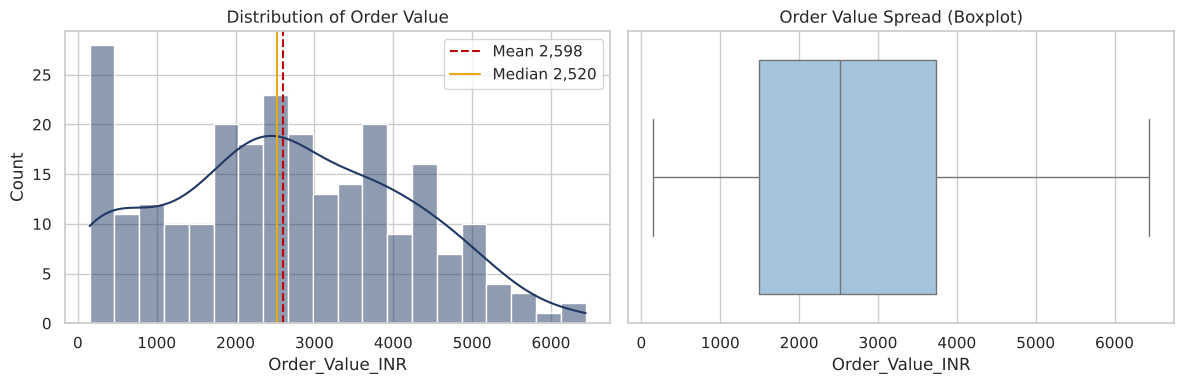

In [8]:
y = clean['Order_Value_INR']
print(y.describe().round(1))
print('Skewness:', round(y.skew(), 2))

q1, q3 = y.quantile(0.25), y.quantile(0.75)
iqr = q3 - q1
outliers = clean[(y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr)]
print('Outliers by the IQR rule:', len(outliers))
print('Orders at the minimum value of Rs 150:', (y == 150).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, bins=20, kde=True, color='#1F3864', ax=ax[0])
ax[0].axvline(y.mean(), color='#C00000', ls='--', label=f'Mean {y.mean():,.0f}')
ax[0].axvline(y.median(), color='#E6A817', label=f'Median {y.median():,.0f}')
ax[0].set_title('Distribution of Order Value'); ax[0].set_xlabel('Order_Value_INR'); ax[0].legend()
sns.boxplot(x=y, color='#9DC3E6', ax=ax[1]); ax[1].set_title('Order Value Spread (Boxplot)')
plt.tight_layout(); plt.savefig('../images/01_overall_order_value.png'); plt.show()

**Q1 answer:** the typical order is about **₹2,520** (median) and the mean is **₹2,598**, which are close, so the shape is almost symmetric (skewness 0.12). The spread is wide (standard deviation ₹1,523, from ₹150 to ₹6,440) and there are **no outliers** by the IQR rule. There is a tall bar at the very left: **21 orders sit exactly at the ₹150 minimum**, which looks like a floor in the data rather than a real shopping pattern.

### Q2. Do items, browsing time, discount and delivery days affect order value?

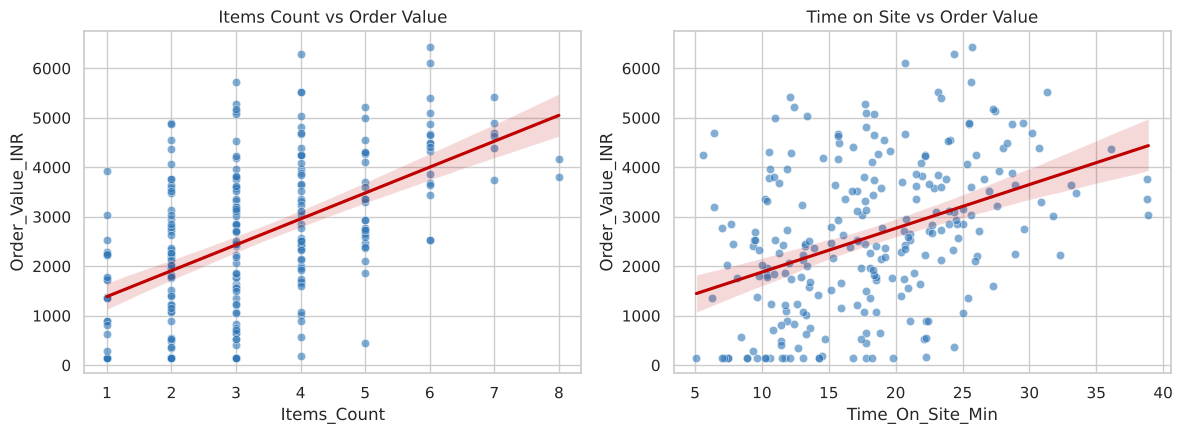

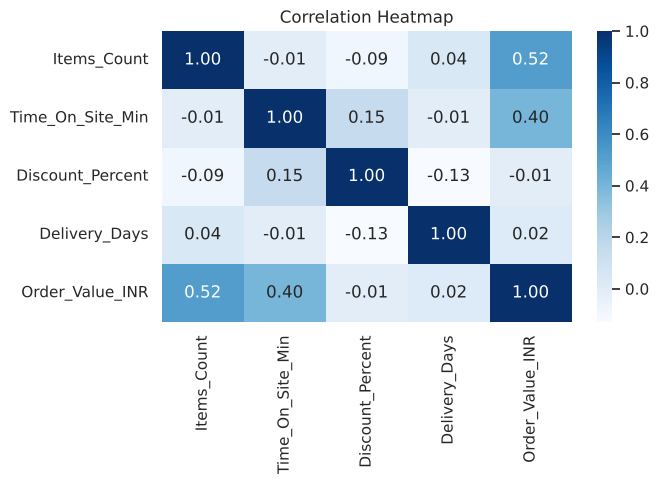

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=clean, x='Items_Count', y='Order_Value_INR', alpha=.6, color='#2E75B6', ax=ax[0])
sns.regplot(data=clean, x='Items_Count', y='Order_Value_INR', scatter=False, color='#C00000', ax=ax[0]); ax[0].set_title('Items Count vs Order Value')
sns.scatterplot(data=clean, x='Time_On_Site_Min', y='Order_Value_INR', alpha=.6, color='#2E75B6', ax=ax[1])
sns.regplot(data=clean, x='Time_On_Site_Min', y='Order_Value_INR', scatter=False, color='#C00000', ax=ax[1]); ax[1].set_title('Time on Site vs Order Value')
plt.tight_layout(); plt.savefig('../images/02_items_time.png'); plt.show()

num_cols = ['Items_Count', 'Time_On_Site_Min', 'Discount_Percent', 'Delivery_Days', 'Order_Value_INR']
plt.figure(figsize=(7, 5))
sns.heatmap(clean[num_cols].corr().round(2), annot=True, cmap='Blues', fmt='.2f'); plt.title('Correlation Heatmap')
plt.tight_layout(); plt.savefig('../images/03_correlation.png'); plt.show()

In [10]:
print(clean[num_cols].corr()['Order_Value_INR'].drop('Order_Value_INR').round(2))
print()
print(clean.groupby('Items_Count')['Order_Value_INR'].agg(['count', 'mean']).round(0))

Items_Count         0.52
Time_On_Site_Min    0.40
Discount_Percent   -0.01
Delivery_Days       0.02
Name: Order_Value_INR, dtype: float64

             count    mean
Items_Count               
1               23  1394.0
2               61  1889.0
3               66  2445.0
4               49  3016.0
5               26  3181.0
6               17  4392.0
7                6  4630.0
8                2  3985.0


               count    mean
Discount_Band               
0-10%             78  2518.0
11-20%           112  2799.0
21-30%            54  2369.0
31-50%             6  1955.0
                count    mean
Delivery_Speed               
Fast               85  2493.0
Standard          146  2632.0
Slow               19  2809.0


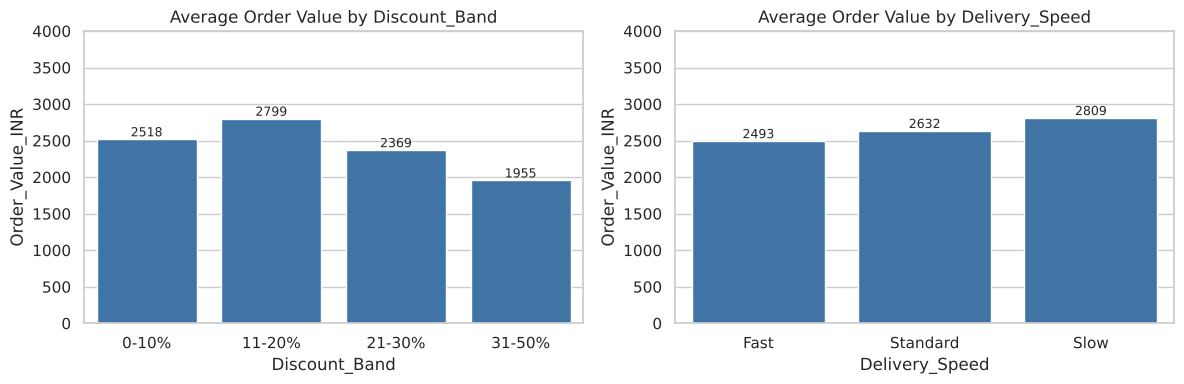

In [11]:
clean['Discount_Band'] = pd.cut(clean['Discount_Percent'], [-1, 10, 20, 30, 50], labels=['0-10%', '11-20%', '21-30%', '31-50%'])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col in zip(ax, ['Discount_Band', 'Delivery_Speed']):
    sns.barplot(data=clean, x=col, y='Order_Value_INR', errorbar=None, color='#2E75B6', ax=a)
    a.set_title(f'Average Order Value by {col}'); a.set_ylim(0, 4000)
    for p in a.patches:
        a.annotate(f'{p.get_height():.0f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.savefig('../images/04_discount_delivery.png'); plt.show()

print(clean.groupby('Discount_Band', observed=True)['Order_Value_INR'].agg(['count', 'mean']).round(0))
print(clean.groupby('Delivery_Speed', observed=True)['Order_Value_INR'].agg(['count', 'mean']).round(0))

**Q2 answer:** `Items_Count` has the strongest link with order value (**r = 0.52**): the average order grows from about ₹1,394 for one item to ₹4,630 for seven items. `Time_On_Site_Min` also helps (**r = 0.40**). `Discount_Percent` (r = -0.01) and `Delivery_Days` (r = 0.02) show **almost no relationship** with order value. The very high discount band (31-50%) has the lowest average, but it holds only 6 orders, so it should not be over-read. These results show association, not cause.

### Q3. Does order value differ by category, city, payment method or customer type?

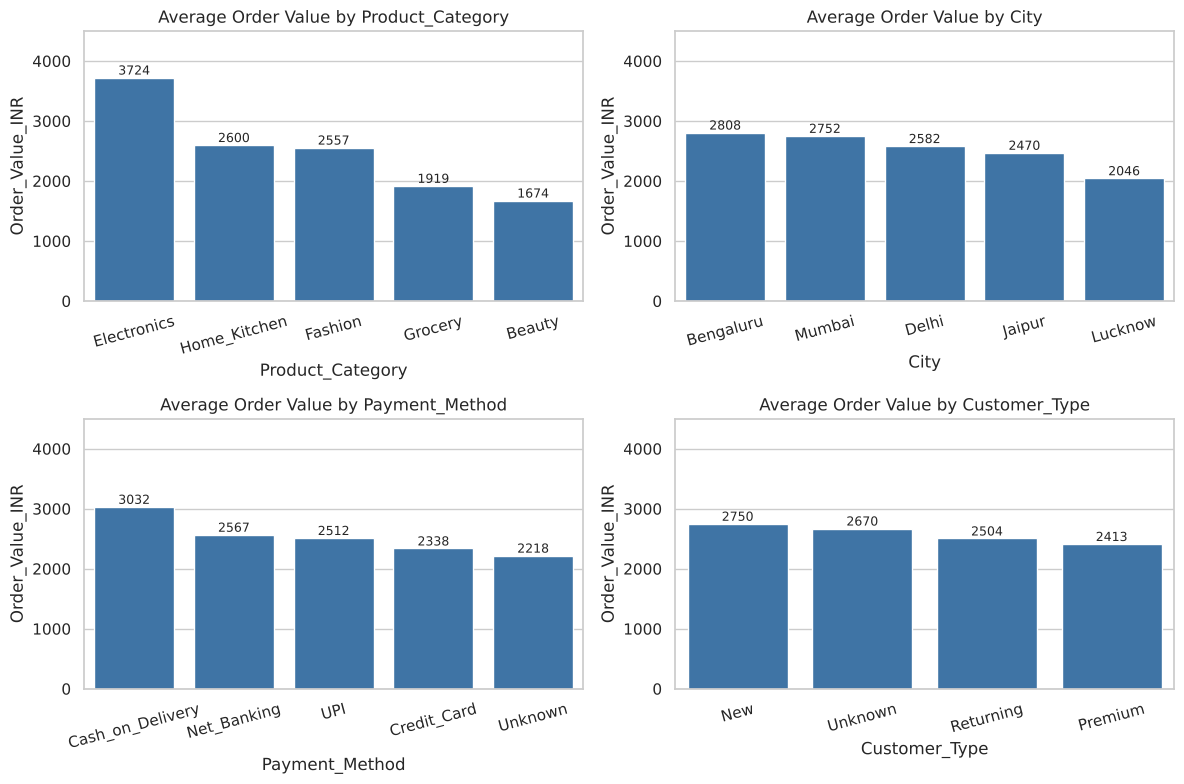

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for a, col in zip(ax.flat, ['Product_Category', 'City', 'Payment_Method', 'Customer_Type']):
    order = clean.groupby(col)['Order_Value_INR'].mean().sort_values(ascending=False).index
    sns.barplot(data=clean, x=col, y='Order_Value_INR', order=order, errorbar=None, color='#2E75B6', ax=a)
    a.set_title(f'Average Order Value by {col}'); a.set_ylim(0, 4500)
    a.tick_params(axis='x', rotation=15)
    for p in a.patches:
        a.annotate(f'{p.get_height():.0f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.savefig('../images/05_group_comparison.png'); plt.show()

In [13]:
for col in ['Product_Category', 'City', 'Payment_Method', 'Customer_Type']:
    print(clean.groupby(col)['Order_Value_INR'].agg(['count', 'mean']).round(0).sort_values('mean', ascending=False))
    print()
print('Average value per item by category:')
print(clean.groupby('Product_Category')['Value_Per_Item'].mean().round(0).sort_values(ascending=False))

                  count    mean
Product_Category               
Electronics          55  3724.0
Home_Kitchen         44  2600.0
Fashion              77  2557.0
Grocery              39  1919.0
Beauty               35  1674.0

           count    mean
City                    
Bengaluru     57  2808.0
Mumbai        73  2752.0
Delhi         59  2582.0
Jaipur        27  2470.0
Lucknow       34  2046.0

                  count    mean
Payment_Method                 
Cash_on_Delivery     61  3032.0
Net_Banking          18  2567.0
UPI                 111  2512.0
Credit_Card          54  2338.0
Unknown               6  2218.0

               count    mean
Customer_Type               
New              104  2750.0
Unknown            5  2670.0
Returning        110  2504.0
Premium           31  2413.0

Average value per item by category:
Product_Category
Electronics     1237.0
Home_Kitchen     976.0
Fashion          821.0
Beauty           578.0
Grocery          511.0
Name: Value_Per_Item, dtype: fl

**Q3 answer:** the biggest gap is by **product category**: Electronics averages **₹3,724**, while Beauty averages only **₹1,674** (Grocery ₹1,919). Electronics orders are large mainly because each item is costly (about ₹1,237 per item against ₹511 for Grocery). Among cities, Bengaluru (₹2,808) and Mumbai (₹2,752) are highest and **Lucknow** is lowest (₹2,046). Cash on Delivery has the highest average (₹3,032) and Credit Card the lowest (₹2,338). Customer type makes a small difference (New ₹2,750, Returning ₹2,504, Premium ₹2,413), and `Unknown` is too small (5 orders) to judge.

### Q4. Which orders are Low Value (below ₹1,500)?

63 orders (25.2%) are Low Value
Average items - low: 2.3 | all orders: 3.32
Average time on site - low: 14.4 min | all orders: 18.1 min


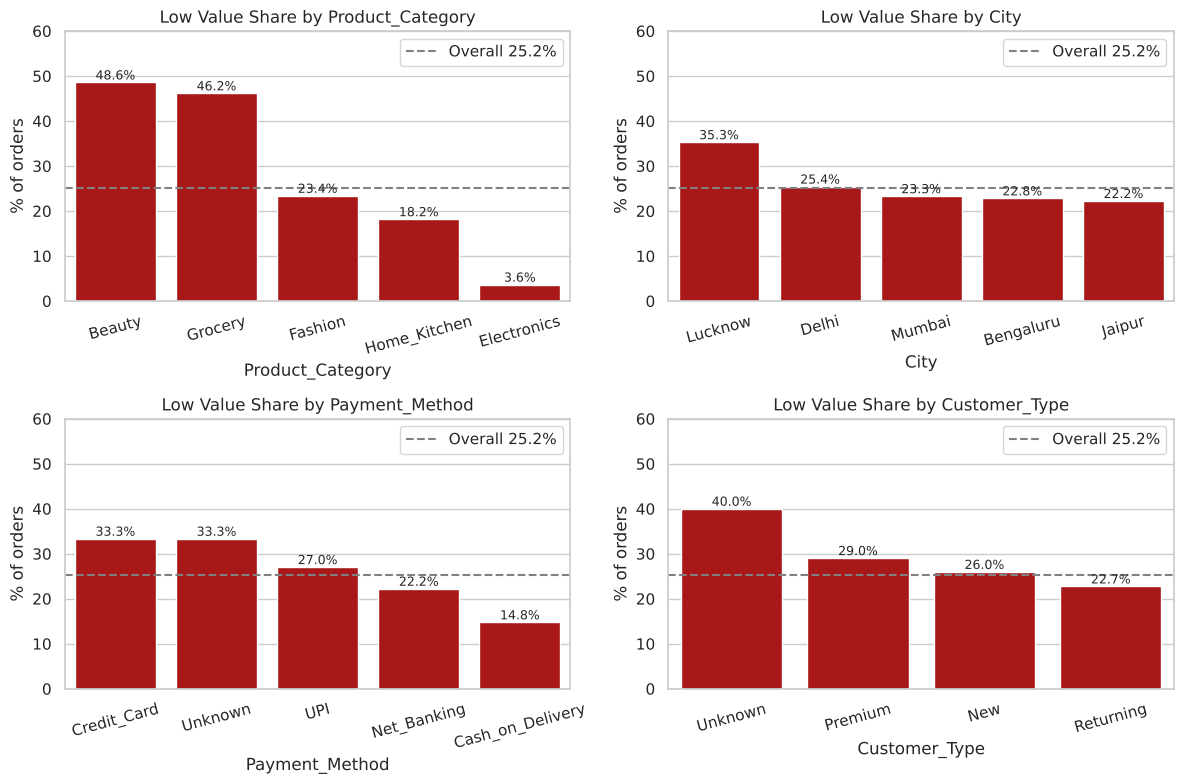

In [14]:
clean['Is_Low'] = (clean['Value_Status'] == 'Low Value')
low = clean[clean['Is_Low']]
print(f'{len(low)} orders ({len(low)/len(clean):.1%}) are Low Value')
print('Average items - low:', round(low['Items_Count'].mean(), 2), '| all orders:', round(clean['Items_Count'].mean(), 2))
print('Average time on site - low:', round(low['Time_On_Site_Min'].mean(), 1), 'min | all orders:', round(clean['Time_On_Site_Min'].mean(), 1), 'min')

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for a, col in zip(ax.flat, ['Product_Category', 'City', 'Payment_Method', 'Customer_Type']):
    share = (clean.groupby(col)['Is_Low'].mean() * 100).sort_values(ascending=False)
    sns.barplot(x=share.index, y=share.values, color='#C00000', ax=a)
    a.axhline(len(low) / len(clean) * 100, color='grey', ls='--', label='Overall 25.2%')
    a.set_title(f'Low Value Share by {col}'); a.set_ylabel('% of orders'); a.set_ylim(0, 60); a.tick_params(axis='x', rotation=15)
    for p in a.patches:
        a.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=9)
    a.legend()
plt.tight_layout(); plt.savefig('../images/06_low_value.png'); plt.show()

In [15]:
for col in ['Product_Category', 'City', 'Payment_Method', 'Customer_Type']:
    t = clean.groupby(col)['Is_Low'].agg(['size', 'sum', 'mean'])
    t.columns = ['orders', 'low_value', 'share']
    print(t.assign(share=(t['share'] * 100).round(1)).sort_values('share', ascending=False))
    print()
low[['Order_ID', 'Product_Category', 'City', 'Items_Count', 'Time_On_Site_Min', 'Order_Value_INR']].sort_values('Order_Value_INR').head(10)

                  orders  low_value  share
Product_Category                          
Beauty                35         17   48.6
Grocery               39         18   46.2
Fashion               77         18   23.4
Home_Kitchen          44          8   18.2
Electronics           55          2    3.6

           orders  low_value  share
City                               
Lucknow        34         12   35.3
Delhi          59         15   25.4
Mumbai         73         17   23.3
Bengaluru      57         13   22.8
Jaipur         27          6   22.2

                  orders  low_value  share
Payment_Method                            
Credit_Card           54         18   33.3
Unknown                6          2   33.3
UPI                  111         30   27.0
Net_Banking           18          4   22.2
Cash_on_Delivery      61          9   14.8

               orders  low_value  share
Customer_Type                          
Unknown             5          2   40.0
Premium            31  

,Order_ID,Product_Category,City,Items_Count,Time_On_Site_Min,Order_Value_INR
0,O1001,Beauty,Lucknow,2,10.6,150
20,O1021,Grocery,Jaipur,1,5.1,150
27,O1028,Grocery,Lucknow,1,7.5,150
65,O1066,Beauty,Bengaluru,3,8.9,150
66,O1067,Beauty,Bengaluru,3,7.5,150
53,O1054,Grocery,Delhi,2,17.8,150
77,O1078,Home_Kitchen,Jaipur,2,10.3,150
71,O1072,Beauty,Jaipur,2,14.3,150
113,O1114,Grocery,Lucknow,1,19.8,150
89,O1090,Electronics,Bengaluru,2,8.9,150


**Q4 answer:** **63 orders (25.2%)** are Low Value. They cluster in **Beauty (48.6% of its orders)** and **Grocery (46.2%)**, while only 3.6% of Electronics orders are low. They also have fewer items (2.3 on average against 3.3 overall) and shorter visits (14.4 minutes against 18.1). By group, **Lucknow** (35.3%) and **Credit Card** payers (33.3%) stand out. Cash on Delivery has the lowest share (14.8%).

## 7. Key insights 

In [16]:
r_items = clean['Items_Count'].corr(clean['Order_Value_INR'])
r_time = clean['Time_On_Site_Min'].corr(clean['Order_Value_INR'])
r_disc = clean['Discount_Percent'].corr(clean['Order_Value_INR'])
r_del = clean['Delivery_Days'].corr(clean['Order_Value_INR'])
cat = clean.groupby('Product_Category')['Order_Value_INR'].mean()
low_share = clean.groupby('Product_Category')['Is_Low'].mean() * 100

print(f"1. Average order value: Rs {clean['Order_Value_INR'].mean():,.0f}; median Rs {clean['Order_Value_INR'].median():,.0f}.")
print(f"2. Items vs value correlation = {r_items:.2f}; time on site = {r_time:.2f}.")
print(f"3. Discount vs value = {r_disc:.2f}; delivery days vs value = {r_del:.2f} (almost no link).")
print(f"4. Highest-value category: {cat.idxmax()} (Rs {cat.max():,.0f}); lowest: {cat.idxmin()} (Rs {cat.min():,.0f}).")
print(f"5. {len(low)} orders ({len(low)/len(clean):.1%}) are Low Value; highest share in {low_share.idxmax()} ({low_share.max():.1f}%).")

1. Average order value: Rs 2,598; median Rs 2,520.
2. Items vs value correlation = 0.52; time on site = 0.40.
3. Discount vs value = -0.01; delivery days vs value = 0.02 (almost no link).
4. Highest-value category: Electronics (Rs 3,724); lowest: Beauty (Rs 1,674).
5. 63 orders (25.2%) are Low Value; highest share in Beauty (48.6%).


## 8. Recommendations

- **Build bigger baskets in Beauty and Grocery.** Items per order is the strongest driver of value, and these two categories hold most low-value orders. Bundles, "add one more item" prompts or a free-delivery limit can lift them.
- **Do not count on deeper discounts to raise order value.** Discount shows almost no link with order value here, so keep the promotion budget for basket-building offers instead.
- **Keep an eye on Lucknow and Credit Card orders.** Both have a higher share of low-value orders than the overall 25.2%. Their groups are small, so check them with more data before changing any plan.

> **Remember:** correlation does not prove causation. This analysis shows association in a synthetic dataset of 250 orders, not cause.

## 9. Save the cleaned data

In [17]:
new_cols = ['Value_Per_Item', 'Order_Segment', 'Delivery_Speed', 'Value_Status', 'Discount_Band', 'Is_Low']

# cleaned file with the original 11 columns
clean.drop(columns=new_cols).to_csv('../data/processed/shopping_data_cleaned.csv', index=False)

# same file with the new columns, ready for analysis
clean.drop(columns=['Discount_Band', 'Is_Low']).to_csv('../data/processed/shopping_data_with_new_columns.csv', index=False)
print('Saved. Rows:', len(clean))

Saved. Rows: 250
